#                                  Limpieza De Datos

## Importando Datos Y Dependencias

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import openai
import os
import warnings

In [3]:
df = pd.read_csv("data/fraudTrain.csv")
warnings.simplefilter("ignore")
df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [4]:
print(f"Se tiene informacion sobre la cantidad de transacciones con  diferentes características {df.shape}")
print(f"La informacion esta en un formato: {df.shape}")

Se tiene informacion sobre la cantidad de transacciones con  diferentes características (1296675, 23)
La informacion esta en un formato: (1296675, 23)


# Verificando Valores Nulos Y Dupicados


In [5]:
print("Número de datos nulos de cada columna: ")
df.isnull().sum()

Número de datos nulos de cada columna: 


Unnamed: 0               0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1296675 non-null  int64  
 1   trans_date_trans_time  1296675 non-null  object 
 2   cc_num                 1296675 non-null  int64  
 3   merchant               1296675 non-null  object 
 4   category               1296675 non-null  object 
 5   amt                    1296675 non-null  float64
 6   first                  1296675 non-null  object 
 7   last                   1296675 non-null  object 
 8   gender                 1296675 non-null  object 
 9   street                 1296675 non-null  object 
 10  city                   1296675 non-null  object 
 11  state                  1296675 non-null  object 
 12  zip                    1296675 non-null  int64  
 13  lat                    1296675 non-null  float64
 14  long              

In [6]:
print("Los datos tienen 0 valores nulos y ", df.duplicated().sum(), "duplicados")
print(f"Las transacciones poseen {len(df.select_dtypes(include=["int64","float64"]).columns)} caracteristicas numéricas y {len(df.select_dtypes(include=["object"]).columns)} categoricas")

Los datos tienen 0 valores nulos y  0 duplicados
Las transacciones poseen 11 caracteristicas numéricas y 12 categoricas


# Modificando Columnas

## Modificando columna trans_date_trans_time


In [8]:
date_year = []
date_month = []
for i in df["trans_date_trans_time"]:
    date_year.append(i.split("-")[0])
    date_month.append(i.split("-")[1])
df["trans_year_time"] = date_year
df["trans_month_time"] =  date_month
df["trans_date_trans_time"] = df["trans_date_trans_time"].str.split(" ").str[0]
df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])
df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud,trans_year_time,trans_month_time
0,0,2019-01-01,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0,2019,01
1,1,2019-01-01,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0,2019,01
2,2,2019-01-01,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0,2019,01
3,3,2019-01-01,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0,2019,01
4,4,2019-01-01,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0,2019,01


## Modificando las columnas First y Last

In [9]:
df[["first","last"]].head()

names = []
for i in zip(df["first"], df["last"]):
    name = i[0] + "_" + i[1]
    names.append(name)
    
df["name"] = names

In [10]:
df.pop("first")
df.pop("last")
df["name"].head()

0    Jennifer_Banks
1    Stephanie_Gill
2    Edward_Sanchez
3      Jeremy_White
4      Tyler_Garcia
Name: name, dtype: object

In [10]:
print("Hay 973 clientes de los cuales Scott_Martin ha sido quien ha realizado mas transacciones ")
df["name"].value_counts().reset_index()

Hay 973 clientes de los cuales Scott_Martin ha sido quien ha realizado mas transacciones 


,name,count
0,Scott_Martin,4618
1,Jeffrey_Smith,3592
2,Barbara_Taylor,3123
3,Monica_Cohen,3123
4,Jessica_Perez,3119
...,...,...
968,Mark_Pennington,7
969,Angelica_Lopez,7
970,Kelly_Lawrence,7
971,Cody_Blake,7


## Modificando columna dob

In [14]:
df["new_dob"] = df["dob"].str.split("-").str[0]
print("Los clientes nacieron entre: "+ df["new_dob"].min() + "-" + df["new_dob"].max())
df["new_dob"] = df["new_dob"].astype(int)
df["age"] = 2020 - df["new_dob"]
print("Los clientes tienen un rango de edad entre: " + str(df["age"].min()) + " a " + str(df["age"].max()))
df.pop("dob")
df.pop("new_dob")
df.head()

Los clientes nacieron entre: 1924-2005
Los clientes tienen un rango de edad entre: 15 a 96


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,city_pop,job,trans_num,unix_time,merch_lat,merch_long,is_fraud,trans_year_time,trans_month_time,age
0,0,2019-01-01,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,3495,"Psychologist, counselling",0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0,2019,01,32
1,1,2019-01-01,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,149,Special educational needs teacher,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0,2019,01,42
2,2,2019-01-01,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,4154,Nature conservation officer,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0,2019,01,58
3,3,2019-01-01,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,1939,Patent attorney,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0,2019,01,53
4,4,2019-01-01,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,99,Dance movement psychotherapist,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0,2019,01,34


In [15]:
def intervalos_edad(edad):
    if edad < 18:
        return "Minor"
    if 18 <= edad < 60:
        return "Adult"
    if edad >= 60:
        return "Elder"
intervalos= []
for i in df["age"]:
    r = intervalos_edad(i)
    intervalos.append(r)

In [16]:
df["cat_age"] = intervalos
df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,job,trans_num,unix_time,merch_lat,merch_long,is_fraud,trans_year_time,trans_month_time,age,cat_age
0,0,2019-01-01,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,"Psychologist, counselling",0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0,2019,01,32,Adult
1,1,2019-01-01,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,Special educational needs teacher,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0,2019,01,42,Adult
2,2,2019-01-01,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,Nature conservation officer,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0,2019,01,58,Adult
3,3,2019-01-01,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,Patent attorney,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0,2019,01,53,Adult
4,4,2019-01-01,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,Dance movement psychotherapist,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0,2019,01,34,Adult


## Modificando Indice

In [17]:
df.set_index("trans_num", inplace=True)
df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,city_pop,job,unix_time,merch_lat,merch_long,is_fraud,trans_year_time,trans_month_time,age,cat_age
trans_num,,,,,,,,,,,,,,,,,,,,,
0b242abb623afc578575680df30655b9,0,2019-01-01,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,3495,"Psychologist, counselling",1325376018,36.011293,-82.048315,0,2019,01,32,Adult
1f76529f8574734946361c461b024d99,1,2019-01-01,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,149,Special educational needs teacher,1325376044,49.159047,-118.186462,0,2019,01,42,Adult
a1a22d70485983eac12b5b88dad1cf95,2,2019-01-01,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,4154,Nature conservation officer,1325376051,43.150704,-112.154481,0,2019,01,58,Adult
6b849c168bdad6f867558c3793159a81,3,2019-01-01,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,1939,Patent attorney,1325376076,47.034331,-112.561071,0,2019,01,53,Adult
a41d7549acf90789359a9aa5346dcb46,4,2019-01-01,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,99,Dance movement psychotherapist,1325376186,38.674999,-78.632459,0,2019,01,34,Adult


## Modificando la columna job

In [25]:
categorias_empleos = {
    "health and medicine": [
        'psychologist, counselling', 'radiographer, diagnostic', 'paediatric nurse',
        'therapist, occupational', 'physiotherapist', 'forensic psychologist',
        'physicist, medical', 'ambulance person', 'clinical biochemist',
        'surgeon', 'diagnostic radiographer', 'medical sales representative',
        'medical physicist', 'chiropodist', 'psychiatric nurse',
        'embryologist, clinical', 'immunologist', 'doctor, hospital',
        'pharmacologist', 'podiatrist'
    ],
    "science and research": [
        'geochemist', 'scientist, research (maths)', 'research officer, trade union',
        'research officer, political party', 'research scientist (physical sciences)',
        'operations geologist', 'engineering geologist', 'agricultural consultant',
        'scientist, audiological', 'environmental consultant', 'hydrologist',
        'toxicologist', 'archaeologist', 'scientist, marine',
        'clinical research associate', 'research scientist (life sciences)',
        'water quality scientist', 'scientist, physiological', 'scientist, biomedical',
        'statistician'
    ],
    "engineering and technology": [
        'engineer, land', 'naval architect', 'energy engineer',
        'electrical engineer', 'engineer, technical sales', 'engineer, electronics',
        'engineer, mining', 'materials engineer', 'engineer, structural',
        'mechanical engineer', 'mining engineer', 'engineer, communications',
        'engineer, control and instrumentation', 'engineer, maintenance',
        'engineer, production', 'engineer, manufacturing',
        'engineer, drilling', 'engineer, petroleum', 'civil engineer, contracting',
        'engineer, building services'
    ],
    "information technology (it) and software development": [
        'it trainer', 'systems developer', 'systems analyst',
        'applications developer', 'database administrator', 'programmer, multimedia',
        'multimedia programmer', 'network engineer', 'telecommunications researcher',
        'programmer, applications', 'manufacturing systems engineer',
        'web designer', 'data scientist', 'it consultant', 'information systems manager'
    ],
    "finance and economics": [
        'corporate investment banker', 'economist', 'financial adviser',
        'financial trader', 'accounting technician', 'pensions consultant',
        'investment analyst', 'chief financial officer', 'futures trader',
        'senior tax professional/tax inspector', 'equities trader',
        'risk analyst', 'investment banker, corporate', 'chartered public finance accountant',
        'investment banker, operational', 'accountant, chartered public finance',
        'accountant, chartered certified', 'tax inspector', 'tax adviser',
        'accountant, chartered'
    ]
}

categorias_empleos.update({
    "education and academia": [
        'special educational needs teacher', 'education officer, museum',
        'english as a second language teacher', 'primary school teacher',
        'teacher, english as a foreign language', 'teacher, early years/pre',
        'secondary school teacher', 'further education lecturer',
        'lecturer, further education', 'teacher, secondary school',
        'teacher, primary school', 'education administrator',
        'lecturer, higher education', 'professor emeritus',
        'associate professor', 'teacher, adult education',
        'tefl teacher', 'community education officer',
        'early years teacher', 'teaching laboratory technician'
    ],
    "marketing, advertising, and sales": [
        'market researcher', 'advertising account executive',
        'advertising account planner', 'copywriter, advertising',
        'sales professional, it', 'sales executive',
        'sales promotion account executive', 'marketing executive',
        'media buyer', 'media planner', 'product manager',
        'retail merchandiser', 'merchandiser, retail',
        'visual merchandiser', 'public relations account executive',
        'public relations officer'
    ],
    "legal and law": [
        'patent attorney', 'solicitor, scotland', 'chartered legal executive (england and wales)',
        'barrister', 'lawyer', 'trade mark attorney', 'legal secretary',
        'licensed conveyancer', "barrister's clerk", 'solicitor'
    ],
    "government and public sector": [
        'public affairs consultant', 'probation officer',
        'armed forces training and education officer',
        'trading standards officer', 'civil service fast streamer',
        'civil service administrator', 'administrator, local government',
        'research officer, political party', 'government and public sector',
        'police officer', 'immigration officer',
        'administrator, charities/voluntary organisations',
        'local government officer', 'public librarian', 'equality and diversity officer',
        'social research officer, government', 'tax inspector'
    ],
    "logistics and transportation": [
        'transport planner', 'freight forwarder',
        'logistics and distribution manager', 'armed forces logistics/support/administrative officer',
        'warehouse manager', 'ship broker'
    ]
})

categorias_empleos.update({
    "construction and infrastructure": [
        'engineer, land', 'naval architect', 'mining engineer',
        'engineer, structural', 'land/geomatics surveyor',
        'building control surveyor', 'commercial/residential surveyor',
        'building surveyor', 'quantity surveyor', 'architect',
        'architectural technologist', 'contractor',
        'civil engineer, contracting', 'engineer, building services',
        'civil engineer, civil (contracting)', 'engineer, drilling',
        'engineer, petroleum', 'site engineer', 'contracting civil engineer'
    ],
    "human resources and business management": [
        'human resources officer', 'training and development officer',
        'administrator', 'pensions consultant', 'pension scheme manager',
        'management consultant', 'company secretary',
        'secretary/administrator', 'personnel officer'
    ],
    "tourism and hospitality": [
        'event organiser', 'tourism officer', 'leisure centre manager',
        'tourist information centre manager', 'public house manager',
        'travel agency manager', 'tour manager', 'restaurant manager, fast food',
        'hotel manager', 'catering manager'
    ],
    "arts, design, and entertainment": [
        'designer, multimedia', 'designer, furniture', 'designer, jewellery',
        'fine artist', 'video editor', 'curator', 'exhibition designer',
        'theatre director', 'product designer', 'film/video editor',
        'designer, ceramics/pottery', 'illustrator', 'designer, industrial/product',
        'designer, interior/spatial', 'set designer', 'designer, television/film set',
        'designer, textile', 'designer, exhibition/display', 'ceramics designer',
        'artist', 'glass blower/designer', 'special effects artist',
        'animator', 'furniture designer', 'conservator, furniture',
        'textile designer', 'art gallery manager'
    ],
    "media and journalism": [
        'programme researcher, broadcasting/film/video', 'editor, magazine features',
        'editor, film/video', 'journalist, newspaper', 'broadcast presenter',
        'radio producer', 'production assistant, radio', 'magazine features editor',
        'magazine journalist', 'media planner', 'press sub', 'producer, radio',
        'television camera operator', 'television floor manager',
        'broadcast engineer', 'media buyer', 'press photographer',
        'broadcast journalist', 'producer, television/film/video',
        'presenter, broadcasting', 'radio broadcast assistant',
        'production assistant, television', 'stage manager',
        'commissioning editor'
    ]
})

categorias_empleos.update({
    "environmental science and conservation": [
        'nature conservation officer', 'arboriculturist', 'geochemist',
        'operations geologist', 'environmental consultant',
        'waste management officer', 'environmental health practitioner',
        'water quality scientist', 'soil scientist', 'hydrogeologist',
        'environmental manager', 'ecologist', 'horticultural consultant',
        'environmental education officer', 'forest/woodland manager',
        'hydrologist', 'conservation officer, historic buildings'
    ],
    "psychology and social work": [
        'psychologist, counselling', 'dance movement psychotherapist',
        'therapist, occupational', 'forensic psychologist', 'counsellor',
        'child psychotherapist', 'educational psychologist',
        'counselling psychologist', 'occupational psychologist',
        'psychologist, sport and exercise', 'psychotherapist, child',
        'psychotherapist', 'psychologist, clinical',
        'clinical psychologist', 'psychotherapist, music',
        'therapist, art', 'therapist, music', 'psychologist, forensic',
        'social researcher', 'therapist, drama',
        'social research officer, government'
    ],
    "sports and physical health": [
        'physiotherapist', 'exercise physiologist', 'sports development officer',
        'therapist, sports', 'sport and exercise psychologist',
        'fitness centre manager', 'physical education teacher'
    ],
    "fashion and textile": [
        'clothing/textile technologist', 'garment/textile technologist',
        'designer, textile', 'fashion designer', 'textile designer'
    ],
    "retail and commerce": [
        'call centre manager', 'retail merchandiser', 'dealer',
        'retail banker', 'retail buyer', 'merchandiser, retail',
        'buyer, industrial', 'buyer, retail', 'retail manager',
        'visual merchandiser', 'sales executive',
        'sales professional, IT', 'sales promotion account executive'
    ]
})

categorias_empleos = {
    "health and medicine": [
        "pathologist",
        "optician, dispensing",
        "paramedic",
        "audiological scientist",
        "health service manager",
        "therapist, horticultural",
        "health visitor",
        "medical secretary",
        "cytogeneticist",
        "health physicist",
        "phytotherapist",
        "horticultural therapist",
        "mental health nurse",
        "nurse, children's",
        "physiological scientist",
        "optometrist",
        "pharmacist, community",
        "music therapist",
        "acupuncturist",
        "hospital doctor",
        "biochemist, clinical",
        "general practice doctor",
        "doctor, general practice",
        "occupational hygienist",
        "occupational therapist",
        "neurosurgeon",
        "orthoptist",
        "dispensing optician",
        "learning disability nurse",
        "radiographer, therapeutic",
        "herbalist",
        "osteopath",
        "hospital pharmacist",
        "biomedical scientist",
        "nutritional therapist",
        "scientist, research (medical)",
        "oncologist",
        "scientist, clinical (histocompatibility and immunogenetics)",
        "medical technical officer",
        "clinical cytogeneticist",
        "homeopath"
    ],
    "science and research": [
        "science writer",
        "product/process development scientist",
        "cytogeneticist",
        "chemist, analytical",
        "scientific laboratory technician",
        "scientist, research (physical sciences)",
        "geneticist, molecular",
        "research scientist (medical)",
        "research scientist (maths)",
        "analytical chemist"
    ],
    "engineering and technology": [
        "water engineer",
        "geologist, engineering",
        "engineer, broadcasting (operations)",
        "engineer, biomedical",
        "technical brewer",
        "structural engineer",
        "electronics engineer",
        "chemical engineer",
        "engineer, agricultural",
        "biomedical engineer",
        "building services engineer",
        "maintenance engineer",
        "engineer, automotive",
        "engineer, civil (contracting)",
        "engineer, aeronautical",
        "engineer, civil (consulting)",
        "engineer, materials",
        "engineer, site"
    ],
    "information technology (it) and software development": [
        "chief technology officer"
    ],
    "finance and economics": [
        "claims inspector/assessor",
        "purchasing manager",
        "insurance underwriter",
        "chartered accountant",
        "insurance claims handler",
        "insurance risk surveyor",
        "insurance broker",
        "comptroller"
    ],
    "education and academia": [
        "education officer, community",
        "higher education careers adviser",
        "administrator, education",
        "teacher, special educational needs",
        "museum education officer",
        "english as a foreign language teacher",
        "academic librarian"
    ],
    "marketing, advertising, and sales": [
        "chief marketing officer",
        "advertising copywriter"
    ],
    "legal and law": [
        "legal and law"
    ],
    "government and public sector": [
        "government and public sector",
        "politician's assistant",
        "race relations officer",
        "armed forces technical officer"
    ],
    "logistics and transportation": [
        "logistics and transportation",
        "pilot, airline",
        "air broker",
        "air cabin crew",
        "airline pilot",
        "air traffic controller"
    ],
    "construction and infrastructure": [
        "construction and infrastructure"
    ],
    "human resources and business management": [
        "human resources and business management",
        "chief executive officer",
        "chief strategy officer",
        "chief operating officer",
        "chief of staff"
    ],
    "tourism and hospitality": [
        "tourism and hospitality",
        "cabin crew",
        "theme park manager"
    ],
    "arts, design, and entertainment": [
        "arts, design, and entertainment",
        "location manager",
        "camera operator",
        "jewellery designer",
        "make",
        "music tutor",
        "private music teacher",
        "musician",
        "dancer"
    ],
    "media and journalism": [
        "media and journalism",
        "writer",
        "editor, commissioning",
        "television production assistant",
        "television/film/video producer"
    ],
    "environmental science and conservation": [
        "environmental science and conservation",
        "tree surgeon",
        "fisheries officer",
        "conservator, museum/gallery",
        "historic buildings inspector/conservation officer",
        "heritage manager",
        "museum/gallery conservator"
    ],
    "psychology and social work": [
        "psychology and social work",
        "careers information officer",
        "volunteer coordinator",
        "development worker, community",
        "charity officer",
        "community development worker",
        "aid worker",
        "advice worker",
        "charity fundraiser"
    ],
    "sports and physical health": [
        "sports and physical health",
        "sports administrator",
        "outdoor activities/education manager"
    ],
    "fashion and textile": [
        "fashion and textile"
    ],
    "retail and commerce": [
        "retail and commerce",
        "bookseller"
    ]
}

categorias_empleos = {
    "health and medicine": [
        'community pharmacist', 'health and safety adviser',
        'pharmacist, hospital', 'health promotion specialist',
        'psychiatrist', 'nurse, mental health', 'veterinary surgeon'
    ],
    "science and research": [
        'animal technologist', 'plant breeder/geneticist',
        'field seismologist', 'geoscientist', 'geophysicist/field seismologist',
        'herpetologist'
    ],
    "engineering and technology": [
        'control and instrumentation engineer', 'manufacturing engineer',
        'production engineer', 'industrial/product designer',
        'metallurgist', 'communications engineer', 'drilling engineer',
        'petroleum engineer', 'aeronautical engineer'
    ],
    "information technology (it) and software development": [],
    "finance and economics": [
        'chartered loss adjuster', 'loss adjuster, chartered'
    ],
    "education and academia": [
        'learning mentor', 'careers adviser'
    ],
    "marketing, advertising, and sales": [],
    "legal and law": [],
    "government and public sector": [
        'prison officer', 'emergency planning/management officer'
    ],
    "logistics and transportation": [],
    "construction and infrastructure": [
        'town planner', 'estate manager/land agent', 'quarry manager'
    ],
    "human resources and business management": [
        'records manager', 'industrial buyer'
    ],
    "tourism and hospitality": [
        'barista'
    ],
    "arts, design, and entertainment": [
        'exhibitions officer, museum/gallery', 'community arts worker',
        'art therapist', 'arts development officer', 'theatre manager',
        'interior and spatial designer', 'administrator, arts'
    ],
    "media and journalism": [
        'copy', 'gaffer'
    ],
    "environmental science and conservation": [
        'amenity horticulturist', 'commercial horticulturist',
        'horticulturist, commercial', 'warden/ranger', 'farm manager'
    ],
    "psychology and social work": [],
    "sports and physical health": [],
    "fashion and textile": [
        'fashion and textile', 'colour technologist'
    ],
    "retail and commerce": [],
    "library and information services": [
        'librarian, public', 'librarian, academic', 'archivist',
        'lexicographer', 'information officer'
    ],
    "surveying and planning": [
        'surveyor, minerals', 'minerals surveyor', 'surveyor, mining',
        'surveyor, land/geomatics', 'surveyor, rural practice',
        'planning and development surveyor', 'rural practice surveyor',
        'hydrographic surveyor', 'surveyor, hydrographic'
    ],
    "others": [
        'interpreter', 'mudlogger', 'cartographer', 'land', 'facilities manager',
        'wellsite geologist', 'sub', 'oceanographer', 'records manager',
        'production manager', 'furniture conservator/restorer',
        'firefighter', 'development worker, international aid',
        'field trials officer', 'geologist, wellsite',
        'seismic interpreter'
    ]
}

In [26]:
def asignar_categoria(job):
    job_lower = job.lower()
    for categoria, empleos in categorias_empleos.items():
        if job_lower in empleos:
            return categoria
    return job  

df["job"] = df["job"].apply(asignar_categoria)
df["job"].replace("Animal nutritionist", "others", inplace=True)
df["job"].replace("Intelligence analyst", "others", inplace=True)
df["job"].replace("Energy manager", "others", inplace=True)
df["job"].replace("Regulatory affairs officer", "others", inplace=True)
df["job"].replace("Museum/gallery exhibitions officer", "library and information services", inplace=True)
df["job"].replace("Operational researcher", "science and research", inplace=True)
df["job"].replace("Landscape architect", "construction and infrastructure", inplace=True)


In [27]:
df["job"].value_counts()

job
health and medicine                                     172798
engineering and technology                              147233
arts, design, and entertainment                         115359
science and research                                    112056
finance and economics                                    96456
psychology and social work                               70167
media and journalism                                     68254
education and academia                                   62255
others                                                   50532
environmental science and conservation                   48171
information technology (it) and software development     47255
government and public sector                             44659
marketing, advertising, and sales                        40518
construction and infrastructure                          40438
human resources and business management                  31821
tourism and hospitality                            

## Modificando la columna amt

In [15]:
pivote= df.pivot_table(index="is_fraud",columns="cat_age",values="amt", aggfunc="mean")
pivote

cat_age,Adult,Elder,Minor
is_fraud,,,
0,69.185373,62.745497,62.065792
1,515.993892,568.621641,551.859500


Text(0.5, 1.0, 'Distribución de las transacciones no fraudulentas')

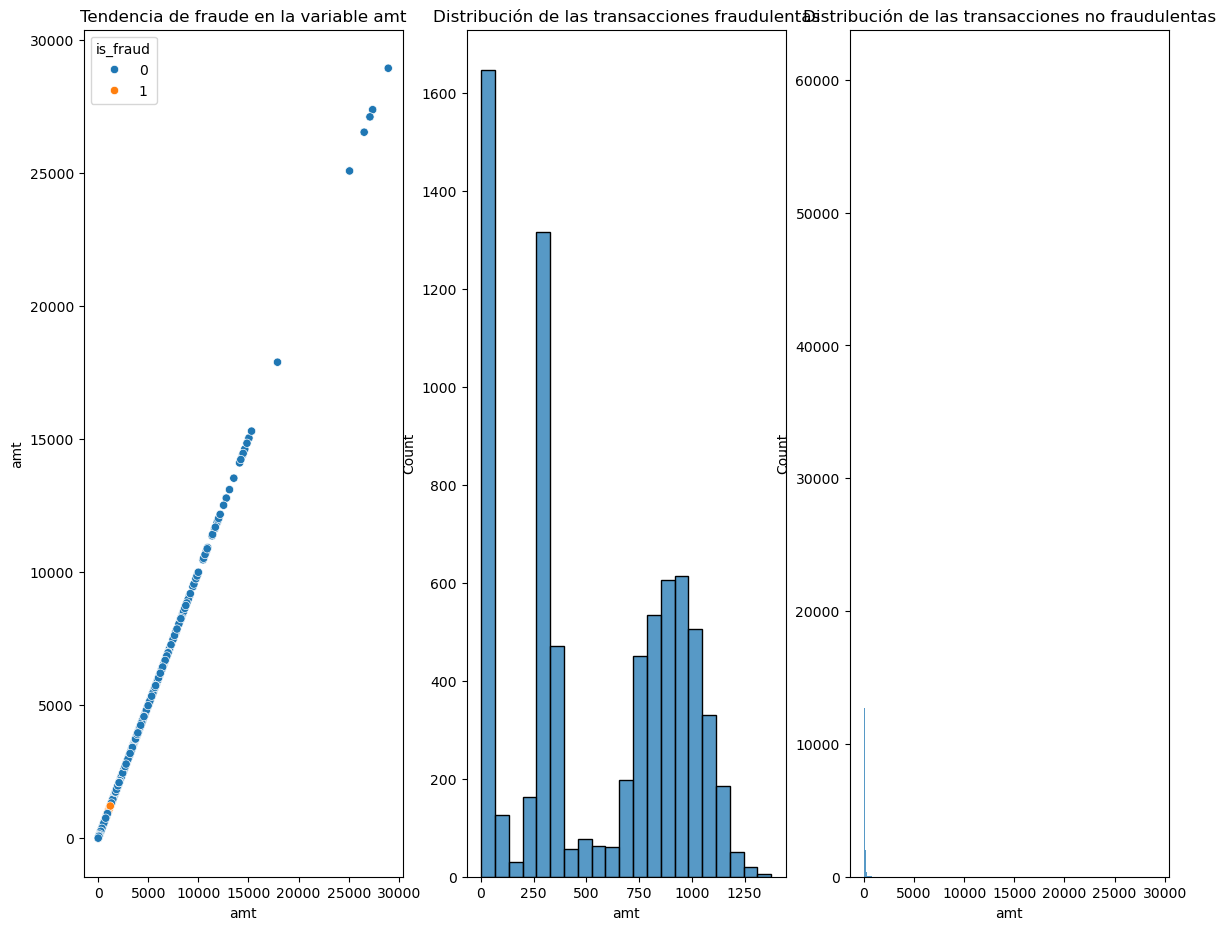

In [16]:
fig, ax = plt.subplots(1,3, figsize=(14,11))

sns.scatterplot(data=df, x="amt", y="amt", hue="is_fraud", ax=ax[0])
ax[0].set_title("Tendencia de fraude en la variable amt")

sns.histplot(df[df["is_fraud"] == 1]["amt"], ax=ax[1])
ax[1].set_title("Distribución de las transacciones fraudulentas")

sns.histplot(df[df["is_fraud"] == 0]["amt"], ax=ax[2])
ax[2].set_title("Distribución de las transacciones no fraudulentas")

In [17]:
q1 = np.percentile(df['amt'], 25)
q2 = np.percentile(df['amt'], 50)  
q3 = np.percentile(df['amt'], 75)
print("Primer quartil de la columna Price: ", q1)
print("Segundo quartil de la columna Price: ", q2)
print("Tercer quartil de la columna Price: ", q3)
iqr = q3 - q1
lim_inf = q1 - 1.5*iqr
lim_sup = q3 + 3*iqr
lim_inf = round(lim_inf)
lim_sup = round(lim_sup)
print('#'*10)
print("Limite inferior del intervalo de confianza: ",lim_inf)
print("Limite superior del intervalo de confianza: ", lim_sup)

Primer quartil de la columna Price:  9.65
Segundo quartil de la columna Price:  47.52
Tercer quartil de la columna Price:  83.14
##########
Limite inferior del intervalo de confianza:  -101
Limite superior del intervalo de confianza:  304


In [18]:
fraud = df[df["is_fraud"] == 1]
print(fraud[fraud["amt"] > 1300].count().sum())
print(len(fraud))

144
7506


In [19]:
raiz = np.sqrt(df["amt"])
log = np.log1p(df["amt"])

Text(0.5, 1.0, 'Distribución de la \n columna amt con \n transformación logaritmica')

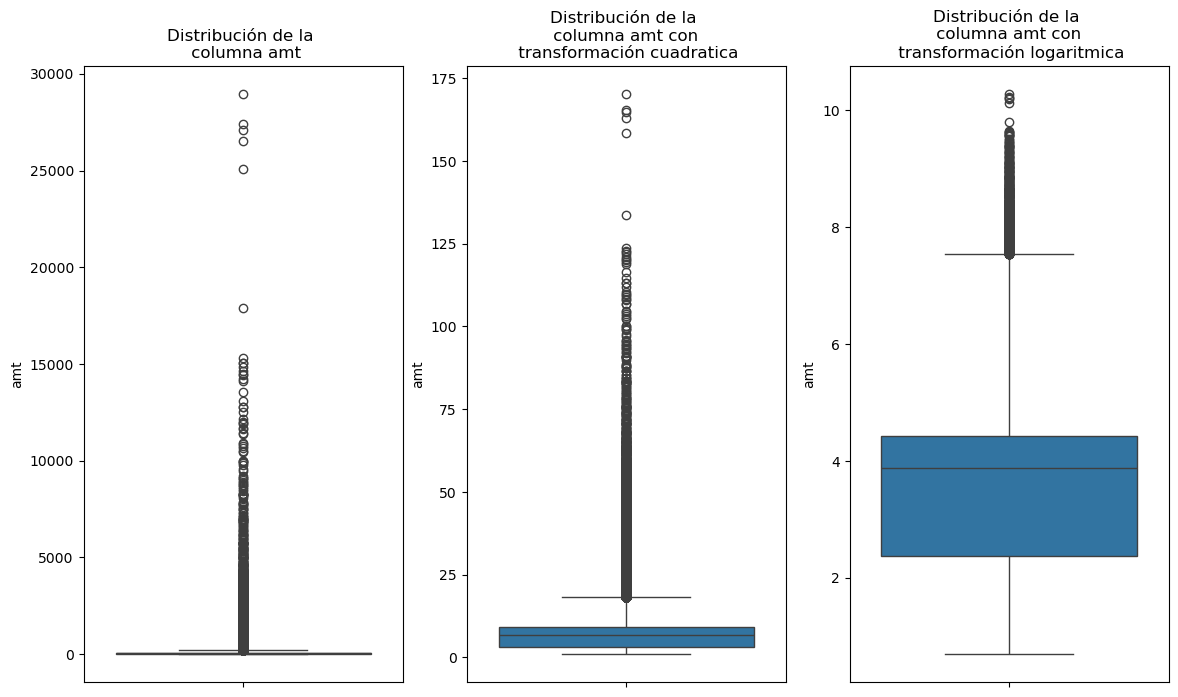

In [20]:
fig, ax = plt.subplots(1,3, figsize=(14,8))

sns.boxplot(df["amt"], ax=ax[0])
ax[0].set_title("Distribución de la \n columna amt")

sns.boxplot(raiz, ax=ax[1])
ax[1].set_title("Distribución de la \n columna amt con \n transformación cuadratica")

sns.boxplot(log, ax=ax[2])
ax[2].set_title("Distribución de la \n columna amt con \n transformación logaritmica")

## Modificando la columna city_pop

In [23]:
print(f"La ciudad mercantil con la poblacion minima es de: {df["city_pop"].min()} \n La ciudad mercantil con la poblacion maxima es de: {df["city_pop"].max()} ")

La ciudad mercantil con la poblacion minima es de: 23 
 La ciudad mercantil con la poblacion maxima es de: 2906700 


In [36]:
print("Media: ", round(df["city_pop"].mean()))
print("Mediana: ", round(df["city_pop"].median()))

print("Media_fraude: ", round(df[df["is_fraud"] == 1]["city_pop"].mean()))
print("Mediana_fraude: ", round(df[df["is_fraud"] == 1]["city_pop"].median()))

print("Media_no_fraude: ", round(df[df["is_fraud"] == 0]["city_pop"].mean()))
print("Mediana_no_fraude: ", round(df[df["is_fraud"] == 0]["city_pop"].median()))

Media:  88824
Mediana:  2456
Media_fraude:  97277
Mediana_fraude:  2623
Media_no_fraude:  88775
Mediana_no_fraude:  2456


In [42]:
df[df["is_fraud"] == 1]["city_pop"].min()
df[df["is_fraud"] == 0]["city_pop"].min()

23

## Modificando columna merchant

In [45]:
df["merchant"].reset_index()

,trans_num,merchant
0,0b242abb623afc578575680df30655b9,"fraud_Rippin, Kub and Mann"
1,1f76529f8574734946361c461b024d99,"fraud_Heller, Gutmann and Zieme"
2,a1a22d70485983eac12b5b88dad1cf95,fraud_Lind-Buckridge
3,6b849c168bdad6f867558c3793159a81,"fraud_Kutch, Hermiston and Farrell"
4,a41d7549acf90789359a9aa5346dcb46,fraud_Keeling-Crist
...,...,...
1296670,440b587732da4dc1a6395aba5fb41669,fraud_Reichel Inc
1296671,278000d2e0d2277d1de2f890067dcc0a,fraud_Abernathy and Sons
1296672,483f52fe67fabef353d552c1e662974c,fraud_Stiedemann Ltd
1296673,d667cdcbadaaed3da3f4020e83591c83,"fraud_Reinger, Weissnat and Strosin"


In [50]:
print("Hay ", len(df["merchant"].unique()), " Diferentes tipos de mercados")

Hay  693  Diferentes tipos de mercados


In [28]:
df["merchant"] = df["merchant"].str.replace("fraud_", "")
df["merchant"].reset_index()

,trans_num,merchant
0,0b242abb623afc578575680df30655b9,"Rippin, Kub and Mann"
1,1f76529f8574734946361c461b024d99,"Heller, Gutmann and Zieme"
2,a1a22d70485983eac12b5b88dad1cf95,Lind-Buckridge
3,6b849c168bdad6f867558c3793159a81,"Kutch, Hermiston and Farrell"
4,a41d7549acf90789359a9aa5346dcb46,Keeling-Crist
...,...,...
1296670,440b587732da4dc1a6395aba5fb41669,Reichel Inc
1296671,278000d2e0d2277d1de2f890067dcc0a,Abernathy and Sons
1296672,483f52fe67fabef353d552c1e662974c,Stiedemann Ltd
1296673,d667cdcbadaaed3da3f4020e83591c83,"Reinger, Weissnat and Strosin"


## Revición final

In [29]:
df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,city_pop,job,unix_time,merch_lat,merch_long,is_fraud,trans_year_time,trans_month_time,age,cat_age
trans_num,,,,,,,,,,,,,,,,,,,,,
0b242abb623afc578575680df30655b9,0,2019-01-01,2703186189652095,"Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,3495,health and medicine,1325376018,36.011293,-82.048315,0,2019,01,32,Adult
1f76529f8574734946361c461b024d99,1,2019-01-01,630423337322,"Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,149,education and academia,1325376044,49.159047,-118.186462,0,2019,01,42,Adult
a1a22d70485983eac12b5b88dad1cf95,2,2019-01-01,38859492057661,Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,4154,environmental science and conservation,1325376051,43.150704,-112.154481,0,2019,01,58,Adult
6b849c168bdad6f867558c3793159a81,3,2019-01-01,3534093764340240,"Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,1939,legal and law,1325376076,47.034331,-112.561071,0,2019,01,53,Adult
a41d7549acf90789359a9aa5346dcb46,4,2019-01-01,375534208663984,Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,99,psychology and social work,1325376186,38.674999,-78.632459,0,2019,01,34,Adult


In [35]:
df.columns

Index(['trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt',
       'gender', 'city', 'state', 'city_pop', 'job', 'merch_lat', 'merch_long',
       'is_fraud', 'trans_year_time', 'trans_month_time', 'age', 'cat_age',
       'name'],
      dtype='object')

In [34]:
df.drop(["unix_time", "long", "lat", "zip", "street", "Unnamed: 0"], axis=1 , inplace=True)

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1296675 entries, 0b242abb623afc578575680df30655b9 to 8f7c8e4ab7f25875d753b422917c98c9
Data columns (total 18 columns):
 #   Column                 Non-Null Count    Dtype         
---  ------                 --------------    -----         
 0   trans_date_trans_time  1296675 non-null  datetime64[ns]
 1   cc_num                 1296675 non-null  int64         
 2   merchant               1296675 non-null  object        
 3   category               1296675 non-null  object        
 4   amt                    1296675 non-null  float64       
 5   gender                 1296675 non-null  object        
 6   city                   1296675 non-null  object        
 7   state                  1296675 non-null  object        
 8   city_pop               1296675 non-null  int64         
 9   job                    1296675 non-null  object        
 10  merch_lat              1296675 non-null  float64       
 11  merch_long             1296675 non-nul

In [37]:
columnas_nuevas = {"trans_date_trans_time": "trans_date",
                   "cc_num": "cc_num",
                   "merchant": "merchant",
                   "category": "type_purcharse",
                   "amt": "amount",
                   "gender": "gender",
                   "city": "city",
                   "state": "state",
                   "city_pop": "city_pop",
                   "merch_lat": "merch_lat",                
                   "merch_long": "merch_long",                 
                   "is_fraud": "fraud",                      
                   "trans_year_time": "trans_year",              
                   "trans_month_time": "trans_month",             
                   "name": "name",                          
                   "age": "age",
                   "cat_age": "age_groups"}
df.rename(columns=columnas_nuevas, inplace = True)
df.head()

,trans_date,cc_num,merchant,type_purcharse,amount,gender,city,state,city_pop,job,merch_lat,merch_long,fraud,trans_year,trans_month,age,age_groups,name
trans_num,,,,,,,,,,,,,,,,,,
0b242abb623afc578575680df30655b9,2019-01-01,2703186189652095,"Rippin, Kub and Mann",misc_net,4.97,F,Moravian Falls,NC,3495,health and medicine,36.011293,-82.048315,0,2019,01,32,Adult,Jennifer_Banks
1f76529f8574734946361c461b024d99,2019-01-01,630423337322,"Heller, Gutmann and Zieme",grocery_pos,107.23,F,Orient,WA,149,education and academia,49.159047,-118.186462,0,2019,01,42,Adult,Stephanie_Gill
a1a22d70485983eac12b5b88dad1cf95,2019-01-01,38859492057661,Lind-Buckridge,entertainment,220.11,M,Malad City,ID,4154,environmental science and conservation,43.150704,-112.154481,0,2019,01,58,Adult,Edward_Sanchez
6b849c168bdad6f867558c3793159a81,2019-01-01,3534093764340240,"Kutch, Hermiston and Farrell",gas_transport,45.00,M,Boulder,MT,1939,legal and law,47.034331,-112.561071,0,2019,01,53,Adult,Jeremy_White
a41d7549acf90789359a9aa5346dcb46,2019-01-01,375534208663984,Keeling-Crist,misc_pos,41.96,M,Doe Hill,VA,99,psychology and social work,38.674999,-78.632459,0,2019,01,34,Adult,Tyler_Garcia


In [78]:
months = {"01":"january", "02":"february", "03":"march", "04":"april", "05":"may", "06":"june", "07":"july", "08":"august", "09":"september", "10":"october", "11":"november", "12":"december"}
df["trans_month"] =df["trans_month"].apply(lambda x: months[x])

In [82]:
df.to_csv('FraudTrainClean.csv')